# Fake Review Detection System

## Project Objective

The objective of this project is to develop a Machine Learning
system that can classify customer reviews as Fake or Genuine.

## Technologies Used

- Python
- Pandas
- NumPy
- Scikit-learn
- NLP
- Machine Learning
- Streamlit

## Basic Workflow

User Review
     ↓
Text Preprocessing
     ↓
TF-IDF
     ↓
Machine Learning Model
     ↓
Prediction
     ↓
Fake Review / Genuine Review

In [ ]:
print("Fake Review Detection System")
print("Project WIP Started")

Fake Review Detection System
Project WIP Started


In [ ]:
# Import the sys module
# sys gives us information about Python
import sys

print("Python Version:") # Display the words "Python Version:"
print(sys.version) # Display the version of Python installed in Colab

Python Version:
3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [ ]:
# Step 6: Checking Pandas, NumPy, and Scikit-learn

import pandas as pd #alias
import numpy as np
import sklearn

print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)
print("Scikit-learn Version:", sklearn.__version__)


Pandas Version: 2.2.3
NumPy Version: 2.1.3
Scikit-learn Version: 1.6.1


In [ ]:
# Step 7: Checking Matplotlib
# Import Matplotlib
# Matplotlib is used for creating graphs

import matplotlib

print("Matplotlib Version:", matplotlib.__version__) # Display the installed Matplotlib version

Matplotlib Version: 3.10.0


In [ ]:
# Step 8: Checking Seaborn
# Import Seaborn
# Seaborn is also used for graphs and visualization

import seaborn as sns

print("Seaborn Version:", sns.__version__) # Display the installed Seaborn version

Seaborn Version: 0.13.2


In [ ]:
import kagglehub #This loads the Kaggle tool. We use it to download the dataset.

path = kagglehub.dataset_download("mexwell/fake-reviews-dataset") #This tells Python:"Download the fake reviews dataset from Kaggle."
print("Dataset downloaded to:", path) #path is simply the location/address of the downloaded dataset.

100%|██████████| 4.78M/4.78M [00:01<00:00, 3.57MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/mexwell/fake-reviews-dataset/versions/1


In [ ]:
import os                #os → helps us work with files and folders
import pandas as pd      #pandas → helps us work with dataset

# Get all files from the dataset folder
files = os.listdir(path)
print("Files in dataset:", files) # Show the names of the files

df = pd.read_csv(os.path.join(path, files[0])) # Read the first file as a CSV dataset
print("Dataset shape:", df.shape) # Show number of rows and columns
df.head() # Show the first 5 rows of the dataset

Files in dataset: ['fake reviews dataset.csv']
Dataset shape: (40432, 4)


,category,rating,label,text_
0,Home_and_Kitchen_5,5.0,CG,"Love this! Well made, sturdy, and very comfor..."
1,Home_and_Kitchen_5,5.0,CG,"love it, a great upgrade from the original. I..."
2,Home_and_Kitchen_5,5.0,CG,This pillow saved my back. I love the look and...
3,Home_and_Kitchen_5,1.0,CG,"Missing information on how to use it, but it i..."
4,Home_and_Kitchen_5,5.0,CG,Very nice set. Good quality. We have had the s...


In [ ]:
# Step 10: Check label distribution
print(df['label'].value_counts())

label
CG    20216
OR    20216
Name: count, dtype: int64


In [ ]:
df.head() # head use for to see first 5 row

,category,rating,label,text_
0,Home_and_Kitchen_5,5.0,CG,"Love this! Well made, sturdy, and very comfor..."
1,Home_and_Kitchen_5,5.0,CG,"love it, a great upgrade from the original. I..."
2,Home_and_Kitchen_5,5.0,CG,This pillow saved my back. I love the look and...
3,Home_and_Kitchen_5,1.0,CG,"Missing information on how to use it, but it i..."
4,Home_and_Kitchen_5,5.0,CG,Very nice set. Good quality. We have had the s...


In [ ]:
df.duplicated().sum()


np.int64(12)

In [ ]:
df.drop_duplicates(inplace = True)

In [ ]:
df.duplicated().sum()

np.int64(0)

### Re-initializing `df`

The `df` DataFrame is currently not defined. This section will re-execute the steps to download the dataset and load it into a pandas DataFrame, ensuring `df` is available for subsequent operations.

In [ ]:
# Import required libraries
import os
import pandas as pd
import kagglehub

# Download the dataset
path = kagglehub.dataset_download("mexwell/fake-reviews-dataset")

# Find the dataset file
files = os.listdir(path)

print("Files in dataset:", files)

# Load the CSV file
df = pd.read_csv(os.path.join(path, files[0]))

# Show basic information
print("Dataset shape:", df.shape)
print("Dataset columns:", df.columns.tolist())

Using Colab cache for faster access to the 'fake-reviews-dataset' dataset.
Files in dataset: ['fake reviews dataset.csv', '.nfs000000007f15ce3900000032']
Dataset shape: (40432, 4)
Dataset columns: ['category', 'rating', 'label', 'text_']


In [ ]:
# Show column names
print(df.columns)

# Show basic information about the dataset
df.info()

# Check if there are missing values
print(df.isnull().sum())

Index(['category', 'rating', 'label', 'text_'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40432 entries, 0 to 40431
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   category  40432 non-null  object 
 1   rating    40432 non-null  float64
 2   label     40432 non-null  object 
 3   text_     40432 non-null  object 
dtypes: float64(1), object(3)
memory usage: 1.2+ MB
category    0
rating      0
label       0
text_       0
dtype: int64


In [ ]:
# This will show the first few actual reviews.
print(df['text_'].head())

0    Love this!  Well made, sturdy, and very comfor...
1    love it, a great upgrade from the original.  I...
2    This pillow saved my back. I love the look and...
3    Missing information on how to use it, but it i...
4    Very nice set. Good quality. We have had the s...
Name: text_, dtype: object


In [ ]:
# Check the unique labels in the dataset

print("Labels:", df['label'].unique())  # CG = Computer-generated reviews → Fake , OR = Original reviews → Genuine

Labels: ['CG' 'OR']


In [ ]:
# Convert dataset labels into easy-to-understand names

df['review_type'] = df['label'].map({
    'CG': 'Fake',
    'OR': 'Genuine'
})

# Display the first 5 rows
df[['label', 'review_type']].head()

,label,review_type
0,CG,Fake
1,CG,Fake
2,CG,Fake
3,CG,Fake
4,CG,Fake


In [ ]:
df['text_'] #df['text_'] means: “Take the text_ column from the dataset df.

,text_
0,"Love this! Well made, sturdy, and very comfor..."
1,"love it, a great upgrade from the original. I..."
2,This pillow saved my back. I love the look and...
3,"Missing information on how to use it, but it i..."
4,Very nice set. Good quality. We have had the s...
...,...
40427,I had read some reviews saying that this bra r...
40428,I wasn't sure exactly what it would be. It is ...
40429,"You can wear the hood by itself, wear it with ..."
40430,I liked nothing about this dress. The only rea...


In [ ]:
# Check for empty review text

empty_reviews = df['text_'].astype(str).str.strip().eq('').sum()

print("Empty reviews:", empty_reviews)

Empty reviews: 0


In [ ]:
import re           # re is Python's regular expression tool. We use it to find and remove unwanted characters.

# Function to clean review text
def clean_text(text):                    # We're creating a function called clean_text.
    text = text.lower()                      # Convert to lowercase
    text = re.sub(r'[^a-z\s]', ' ', text)   # Replace unwanted characters with a space
    text = re.sub(r'\s+', ' ', text)        # Remove extra spaces
    return text.strip()                     # Remove spaces at beginning/end

In [ ]:
# Test the cleaning function on one review

original_review = df['text_'].iloc[0]
cleaned_review = clean_text(original_review)

print("Original Review:",original_review)

print("\nCleaned Review:",cleaned_review)


Original Review: Love this!  Well made, sturdy, and very comfortable.  I love it!Very pretty

Cleaned Review: love this well made sturdy and very comfortable i love it very pretty


In [ ]:
# Clean all reviews and store them in a new column

df['cleaned_text'] = df['text_'].apply(clean_text)

print("Text cleaning completed!")

Text cleaning completed!


In [ ]:
# Compare original and cleaned reviews

print("Original Review:")
print(df['text_'].iloc[0])

print("\nCleaned Review:")
print(df['cleaned_text'].iloc[0])

Original Review:
Love this!  Well made, sturdy, and very comfortable.  I love it!Very pretty

Cleaned Review:
love this well made sturdy and very comfortable i love it very pretty


In [ ]:
print(df.columns)

Index(['category', 'rating', 'label', 'text_', 'review_type', 'cleaned_text'], dtype='object')


In [ ]:
df['cleaned_text'] = df['text_'].apply(clean_text)
print("Text cleaning completed!")

Text cleaning completed!


In [ ]:
print("Original Review:")
print(df['text_'].iloc[0])

print("\nCleaned Review:")
print(df['cleaned_text'].iloc[0])

Original Review:
Love this!  Well made, sturdy, and very comfortable.  I love it!Very pretty

Cleaned Review:
love this well made sturdy and very comfortable i love it very pretty


In [ ]:
print(df.columns)

Index(['category', 'rating', 'label', 'text_', 'review_type', 'cleaned_text'], dtype='object')


In [ ]:
import nltk

print("NLTK is installed and ready!")

NLTK is installed and ready!


In [ ]:
# Take one cleaned review
sample_review = df['cleaned_text'].iloc[0]

# Split the review into individual words
tokens = sample_review.split()

print("Cleaned Review:")
print(sample_review)

print("\nTokens:")
print(tokens)

Cleaned Review:
love this well made sturdy and very comfortable i love it very pretty

Tokens:
['love', 'this', 'well', 'made', 'sturdy', 'and', 'very', 'comfortable', 'i', 'love', 'it', 'very', 'pretty']


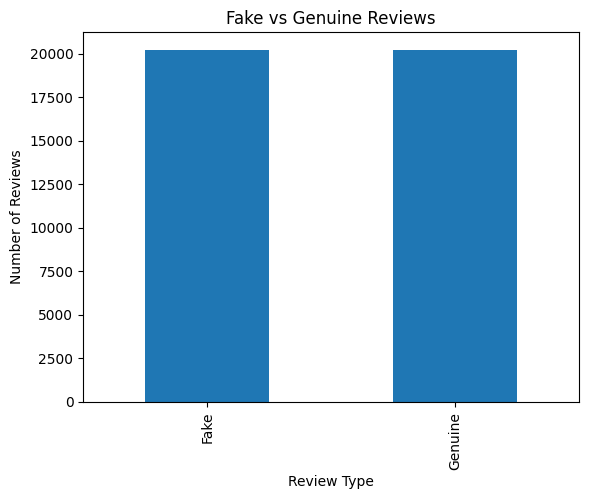

In [ ]:
import matplotlib.pyplot as plt

# Count fake and genuine reviews
review_counts = df['review_type'].value_counts()

# Create a bar chart
review_counts.plot(kind='bar')

plt.title("Fake vs Genuine Reviews")
plt.xlabel("Review Type")
plt.ylabel("Number of Reviews")

plt.show()

In [ ]:
import re

# Clean the review text
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

# Create cleaned_text column
df['cleaned_text'] = df['text_'].apply(clean_text)

# Check the result
print(df[['text_', 'cleaned_text']].head())

                                               text_  \
0  Love this!  Well made, sturdy, and very comfor...   
1  love it, a great upgrade from the original.  I...   
2  This pillow saved my back. I love the look and...   
3  Missing information on how to use it, but it i...   
4  Very nice set. Good quality. We have had the s...   

                                        cleaned_text  
0  love this well made sturdy and very comfortabl...  
1  love it a great upgrade from the original i ve...  
2  this pillow saved my back i love the look and ...  
3  missing information on how to use it but it is...  
4  very nice set good quality we have had the set...  


In [ ]:
# Count the number of words in each review

df['review_length'] = df['cleaned_text'].apply(lambda x: len(x.split()))

# Show the first 5 reviews and their word count
print(df[['cleaned_text', 'review_length']].head())

                                        cleaned_text  review_length
0  love this well made sturdy and very comfortabl...             13
1  love it a great upgrade from the original i ve...             17
2  this pillow saved my back i love the look and ...             14
3  missing information on how to use it but it is...             17
4  very nice set good quality we have had the set...             18


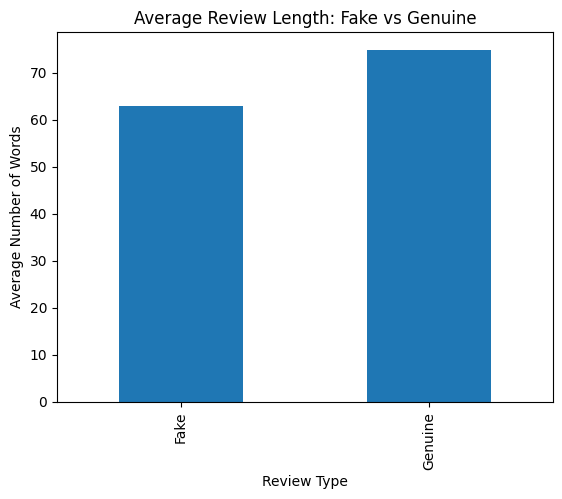

In [ ]:
import matplotlib.pyplot as plt

# Find the average review length for Fake and Genuine reviews
average_length = df.groupby('review_type')['review_length'].mean()

# Create a bar graph
average_length.plot(kind='bar')

plt.title("Average Review Length: Fake vs Genuine")
plt.xlabel("Review Type")
plt.ylabel("Average Number of Words")

plt.show()

In [ ]:
# Check the number of Fake and Genuine reviews for each rating

rating_counts = pd.crosstab(df['rating'], df['review_type'])

print(rating_counts)

review_type   Fake  Genuine
rating                     
1.0           1063     1092
2.0            962     1005
3.0           1952     1834
4.0           3920     4045
5.0          12319    12240


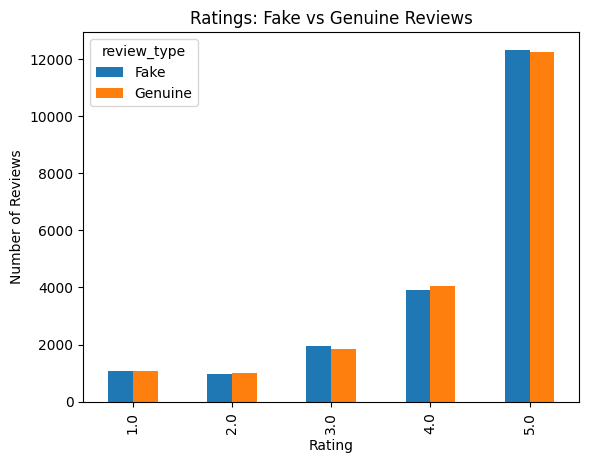

In [ ]:
import matplotlib.pyplot as plt

# Count Fake and Genuine reviews for each rating
rating_counts = pd.crosstab(df['rating'], df['review_type'])

# Create a bar graph
rating_counts.plot(kind='bar')

plt.title("Ratings: Fake vs Genuine Reviews")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# X = input review text
X = df['cleaned_text']

# y = output/target
y = df['review_type']

# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the sizes
print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

Training reviews: 32345
Testing reviews: 8087


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF Vectorizer
tfidf = TfidfVectorizer()

# Learn from training reviews and convert them into numbers
X_train_tfidf = tfidf.fit_transform(X_train)

# Convert testing reviews using the same TF-IDF
X_test_tfidf = tfidf.transform(X_test)

# Check the size
print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (32345, 35147)
Testing data shape: (8087, 35147)


In [ ]:
from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=1000)

# Train the model (Note: Make sure to run the split and TF-IDF cells above first!)
try:
    model.fit(X_train_tfidf, y_train)
    print("Model training completed successfully!")
except NameError as e:
    print(f"Error: {e}")
    print("Please run the cells above for data splitting and TF-IDF vectorization before running this cell.")

Model training completed successfully!


In [ ]:
# Make predictions on the test data
y_pred = model.predict(X_test_tfidf)

print("Predictions completed successfully!")

Predictions completed successfully!


In [ ]:
# Check how many predictions are correct.
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred) # Meaning: Accuracy tells us the percentage of correct predictions.

print("Accuracy:", accuracy)

Accuracy: 0.9034252504018796


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        Fake       0.92      0.89      0.90      4044
     Genuine       0.89      0.92      0.90      4043

    accuracy                           0.90      8087
   macro avg       0.90      0.90      0.90      8087
weighted avg       0.90      0.90      0.90      8087



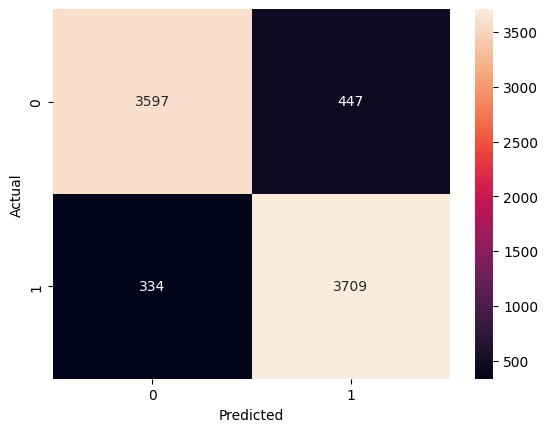

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
review = ["The product is amazing and works perfectly!"]

In [ ]:
print([name for name in globals() if 'tfidf' in name.lower()])

['TfidfVectorizer', 'tfidf', 'X_train_tfidf', 'X_test_tfidf']


In [ ]:
review_tfidf = tfidf.transform(review)
print("Review converted successfully!")

Review converted successfully!


In [ ]:
prediction = model.predict(review_tfidf)

print("Prediction:", prediction[0])

Prediction: Fake


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 90.34 %


In [ ]:
import joblib

joblib.dump(model, "fake_review_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("TF-IDF saved successfully!")

TF-IDF saved successfully!


In [ ]:
from google.colab import files
files.download("fake_review_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("tfidf_vectorizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(df['review_type'].value_counts())
print(df[['text_', 'review_type']].head(10))

review_type
Fake       20216
Genuine    20216
Name: count, dtype: int64
                                               text_ review_type
0  Love this!  Well made, sturdy, and very comfor...        Fake
1  love it, a great upgrade from the original.  I...        Fake
2  This pillow saved my back. I love the look and...        Fake
3  Missing information on how to use it, but it i...        Fake
4  Very nice set. Good quality. We have had the s...        Fake
5       I WANTED DIFFERENT FLAVORS BUT THEY ARE NOT.        Fake
6  They are the perfect touch for me and the only...        Fake
7  These done fit well and look great.  I love th...        Fake
8  Great big numbers & easy to read, the only thi...        Fake
9  My son loves this comforter and it is very wel...        Fake


In [ ]:
print('df' in globals())

True


In [ ]:
print("Fake label examples:")
print(df[df['review_type'] == 'Fake']['text_'].head(3).to_list())

print("\nGenuine label examples:")
print(df[df['review_type'] == 'Genuine']['text_'].head(3).to_list())

Fake label examples:
['Love this!  Well made, sturdy, and very comfortable.  I love it!Very pretty', "love it, a great upgrade from the original.  I've had mine for a couple of years", 'This pillow saved my back. I love the look and feel of this pillow.']

Genuine label examples:
['These are just perfect, exactly what I was looking for.', "Such a great purchase can't beat it for the price", 'What can you say--- cheap and it works as intended.']


In [ ]:
print("Label classes:", model.classes_)

Label classes: ['Fake' 'Genuine']


In [ ]:
test_reviews = [
    "Amazing product! Best ever! Everyone must buy it immediately!",
    "The product works as described, but the battery life is poor.",
    "Terrible quality. It stopped working after one day.",
    "Perfect perfect perfect! Best product ever! Five stars!"
]

for review in test_reviews:
    features = tfidf.transform([review])
    prediction = model.predict(features)[0]

    print("Review:", review)
    print("Prediction:", prediction)

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(features)[0]
        print("Probabilities:", dict(zip(model.classes_, probabilities.round(3))))

    print("-" * 40)

SyntaxError: unterminated string literal (detected at line 5) (2454052780.py, line 5)

In [ ]:
print("Dataset label counts:")
print(df['review_type'].value_counts())

print("\nModel classes:")
print(model.classes_)

Dataset label counts:
review_type
Fake       20216
Genuine    20216
Name: count, dtype: int64

Model classes:
['Fake' 'Genuine']


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Transform the raw text data using the trained TF-IDF vectorizer first
X_test_tfidf = tfidf.transform(X_test)

# Make predictions using the vectorized test data
y_pred = model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=model.classes_))

Accuracy: 0.9034252504018796

Classification Report:
              precision    recall  f1-score   support

        Fake       0.92      0.89      0.90      4044
     Genuine       0.89      0.92      0.90      4043

    accuracy                           0.90      8087
   macro avg       0.90      0.90      0.90      8087
weighted avg       0.90      0.90      0.90      8087


Confusion Matrix:
[[3597  447]
 [ 334 3709]]


In [ ]:
print("X_test type:", type(X_test))
print("X_test sample:")
print(X_test.head())

print("\nY_test sample:")
print(y_test.head())

X_test type: <class 'pandas.core.series.Series'>
X_test sample:
33059    incredibly horrible quality and detail period ...
19898     minimal attractactant if any cats are very picky
38225    promptly delivers no qualms about anything els...
29581    what can i say another word about the book i r...
1079     serious off gassing ugh not only do you have t...
Name: cleaned_text, dtype: object

Y_test sample:
33059    Genuine
19898       Fake
38225    Genuine
29581       Fake
1079        Fake
Name: review_type, dtype: object


In [ ]:
X_test_tfidf = tfidf.transform(X_test)

y_pred = model.predict(X_test_tfidf)

print("Test predictions completed successfully!")

Test predictions completed successfully!


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=model.classes_))

Accuracy: 0.9034252504018796

Classification Report:
              precision    recall  f1-score   support

        Fake       0.92      0.89      0.90      4044
     Genuine       0.89      0.92      0.90      4043

    accuracy                           0.90      8087
   macro avg       0.90      0.90      0.90      8087
weighted avg       0.90      0.90      0.90      8087


Confusion Matrix:
[[3597  447]
 [ 334 3709]]


In [ ]:
import joblib

joblib.dump(model, "fake_review_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [ ]:

# Predict the existing test reviews
test_predictions = model.predict(X_test_tfidf)

# Find Fake reviews correctly predicted as Fake
fake_examples = X_test[
    (y_test == "Fake") & (test_predictions == "Fake")
]

print("Number of correctly detected Fake reviews:", len(fake_examples))
print("\nHere are 5 examples:\n")

for review in fake_examples.head(5):
    print("-", review)
    print("-" * 60)

Number of correctly detected Fake reviews: 3597

Here are 5 examples:

- what can i say another word about the book i really enjoyed this book i am a big fan of the harry bosch
------------------------------------------------------------
- a mind is a terrible thing the only way you can be a good person is to live i had a friend who was a social worker and she had a very large family she had her own apartment which was very small i had to move in and have the people i knew and loved come to live in my apartment i had to live with them all i had to have them all i had to have them all it was very sad i had to be a part of the family i had to have them all there are so many stories of this family especially from the beginning of the book i wanted to be part of this family i wanted to live with them all it was sad i wanted to live with them all it was very sad i wanted to live with them all i really enjoyed the book it was very well written it was very well written it was very well writte

In [ ]:
review = fake_examples.iloc[0]

features = tfidf.transform([review])
prediction = model.predict(features)[0]

print("Review:", review)
print("Colab prediction:", prediction)

if hasattr(model, "predict_proba"):
    probabilities = model.predict_proba(features)[0]
    print("Probabilities:", dict(zip(model.classes_, probabilities.round(3))))

Review: what can i say another word about the book i really enjoyed this book i am a big fan of the harry bosch
Colab prediction: Fake
Probabilities: {'Fake': np.float64(0.614), 'Genuine': np.float64(0.386)}


In [ ]:

# Get predictions for the existing test dataset
test_predictions = model.predict(X_test_tfidf)

# Find correctly predicted Fake and Genuine reviews
correct_fake = X_test[
    (y_test == "Fake") & (test_predictions == "Fake")
]

correct_genuine = X_test[
    (y_test == "Genuine") & (test_predictions == "Genuine")
]

print("=" * 70)
print("5 FAKE REVIEWS")
print("=" * 70)

for i, review in enumerate(correct_fake.head(5), 1):
    print(f"\nFake Review {i}:")
    print(review)

print("\n" + "=" * 70)
print("5 GENUINE REVIEWS")
print("=" * 70)

for i, review in enumerate(correct_genuine.head(5), 1):
    print(f"\nGenuine Review {i}:")
    print(review)

5 FAKE REVIEWS

Fake Review 1:
what can i say another word about the book i really enjoyed this book i am a big fan of the harry bosch

Fake Review 2:
a mind is a terrible thing the only way you can be a good person is to live i had a friend who was a social worker and she had a very large family she had her own apartment which was very small i had to move in and have the people i knew and loved come to live in my apartment i had to live with them all i had to have them all i had to have them all it was very sad i had to be a part of the family i had to have them all there are so many stories of this family especially from the beginning of the book i wanted to be part of this family i wanted to live with them all it was sad i wanted to live with them all it was very sad i wanted to live with them all i really enjoyed the book it was very well written it was very well written it was very well written it was very well written it was very well written it was very well written i really enj

In [ ]:
import joblib
import os

# Safely load the model and vectorizer from disk
if os.path.exists("fake_review_model.pkl") and os.path.exists("tfidf_vectorizer.pkl"):
    model = joblib.load("fake_review_model.pkl")
    tfidf = joblib.load("tfidf_vectorizer.pkl")
    print("Model and TF-IDF Vectorizer loaded successfully!")
else:
    print("Saved files not found. Make sure to run the training cells first.")

# Get predictions for the test data
X_test_tfidf = tfidf.transform(X_test)
test_predictions = model.predict(X_test_tfidf)

# Find 10 correctly predicted Fake reviews
fake_reviews = X_test[
    (y_test == "Fake") & (test_predictions == "Fake")
].head(10)

# Find 10 correctly predicted Genuine reviews
genuine_reviews = X_test[
    (y_test == "Genuine") & (test_predictions == "Genuine")
].head(10)

print("\n===== 10 FAKE REVIEWS =====")
for i, review in enumerate(fake_reviews, 1):
    print(f"{i}. {review}")

print("\n===== 10 GENUINE REVIEWS =====")
for i, review in enumerate(genuine_reviews, 1):
    print(f"{i}. {review}")

Model and TF-IDF Vectorizer loaded successfully!

===== 10 FAKE REVIEWS =====
1. what can i say another word about the book i really enjoyed this book i am a big fan of the harry bosch
2. a mind is a terrible thing the only way you can be a good person is to live i had a friend who was a social worker and she had a very large family she had her own apartment which was very small i had to move in and have the people i knew and loved come to live in my apartment i had to live with them all i had to have them all i had to have them all it was very sad i had to be a part of the family i had to have them all there are so many stories of this family especially from the beginning of the book i wanted to be part of this family i wanted to live with them all it was sad i wanted to live with them all it was very sad i wanted to live with them all i really enjoyed the book it was very well written it was very well written it was very well written it was very well written it was very well written 

In [ ]:

# 20 short Gen-Z-style reviews

sample_reviews = {
    "Fake-style": [
        "Best ever omg!!",
        "Love it so much!",
        "Must buy fr!!",
        "Wowww so good!!",
        "Best product everrr!",
        "100% love this!!",
        "Just buy it!!",
        "Amazinggg product!",
        "Totally worth it!!",
        "Obsessed with this!"
    ],
    "Genuine-style": [
        "Works fine for me.",
        "Good for the price.",
        "Looks like the photo.",
        "A bit too small.",
        "Came one day late.",
        "It works as expected.",
        "Nice, but not perfect.",
        "The size fits well.",
        "Good, but feels cheap.",
        "I use it every day."
    ]
}

# Test every review using your trained backend

for category, reviews in sample_reviews.items():
    print(f"\n===== {category} =====")

    for review in reviews:
        features = tfidf.transform([review])
        prediction = model.predict(features)[0]

        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba(features)[0]
            confidence = max(probabilities) * 100
            print(f"Review: {review}")
            print(f"Prediction: {prediction}")
            print(f"Confidence: {confidence:.2f}%\n")
        else:
            print(f"Review: {review}")
            print(f"Prediction: {prediction}\n")


===== Fake-style =====
Review: Best ever omg!!
Prediction: Genuine
Confidence: 85.53%

Review: Love it so much!
Prediction: Genuine
Confidence: 96.37%

Review: Must buy fr!!
Prediction: Genuine
Confidence: 84.25%

Review: Wowww so good!!
Prediction: Genuine
Confidence: 94.07%

Review: Best product everrr!
Prediction: Genuine
Confidence: 75.96%

Review: 100% love this!!
Prediction: Fake
Confidence: 60.28%

Review: Just buy it!!
Prediction: Genuine
Confidence: 66.84%

Review: Amazinggg product!
Prediction: Genuine
Confidence: 57.01%

Review: Totally worth it!!
Prediction: Genuine
Confidence: 96.39%

Review: Obsessed with this!
Prediction: Genuine
Confidence: 77.17%


===== Genuine-style =====
Review: Works fine for me.
Prediction: Genuine
Confidence: 90.33%

Review: Good for the price.
Prediction: Fake
Confidence: 54.23%

Review: Looks like the photo.
Prediction: Genuine
Confidence: 91.43%

Review: A bit too small.
Prediction: Fake
Confidence: 97.25%

Review: Came one day late.
Predicti

In [ ]:
# Check the model's predictions for short reviews

test_reviews = [
    "Best ever omg!!",
    "Love it so much!",
    "Works fine for me.",
    "Good for the price."
]

for review in test_reviews:
    features = tfidf.transform([review])
    prediction = model.predict(features)[0]

    print("Review:", review)
    print("Prediction:", prediction)
    print("-" * 30)

Review: Best ever omg!!
Prediction: Genuine
------------------------------
Review: Love it so much!
Prediction: Genuine
------------------------------
Review: Works fine for me.
Prediction: Genuine
------------------------------
Review: Good for the price.
Prediction: Fake
------------------------------


In [ ]:
# Find short reviews correctly predicted by your model

X_test_tfidf = tfidf.transform(X_test)
predictions = model.predict(X_test_tfidf)

results = pd.DataFrame({
    "Review": X_test,
    "Actual": y_test,
    "Predicted": predictions
})

# Find short, correctly predicted Fake reviews
fake = results[
    (results["Actual"] == "Fake") &
    (results["Predicted"] == "Fake") &
    (results["Review"].str.split().str.len() <= 10)
]

# Find short, correctly predicted Genuine reviews
genuine = results[
    (results["Actual"] == "Genuine") &
    (results["Predicted"] == "Genuine") &
    (results["Review"].str.split().str.len() <= 10)
]

print("===== SHORT FAKE REVIEWS =====")
print(fake["Review"].head(10).to_string(index=False))

print("\n===== SHORT GENUINE REVIEWS =====")
print(genuine["Review"].head(10).to_string(index=False))

===== SHORT FAKE REVIEWS =====
great story good reading couldn t put the book ...
    beautiful rug ive had it for years and love it
works great very bright easy to use easy to pro...

===== SHORT GENUINE REVIEWS =====
love them very comfortable with roomy pockets n...
nice simple kit i can use during my computer bu...
nice looking well made comfortable folds and tr...
great rock for great price works great for frag...
best price very large units too large for cuttl...
      good size my lb dogs love the size excellent
    used it a handful of times already does it job
works great sure a lot less stressed in the veh...
a great product from a company that knows arche...
five stars check out all her other awesome book...
